**Не зафиксировал объективно, повлияля ли видеокарта на скорость обчения. Поэтому лучше перед выполнением ячеек всё же переключиться на графический процессор.**

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Тетрадка выполнена с исходными данными и параметрами преподавателя: adding problem — 5 000 обучающих и 1 000
> валидационных последовательностей, 30 эпох; классификация тональности — датасет `Megnis/ru_sentiment_dataset-50000`
> с HuggingFace (загрузка `datasets.load_dataset`), разбиение 80/10/10, 10 эпох.
>
> **Исправление ошибки заготовки.** В заготовке и словарь, и обучающий набор `train_ds` строились из `train_data` —
> всего датасета, включая валидационную и тестовую части (утечка: модель училась на тех же отзывах, по которым её
> потом оценивали). Здесь словарь и `train_ds` строятся только по обучающей части `train_data_split`.
>
> Выполнены все «задания для интерпретации», включая дополнительные (длина 200, размер скрытого состояния и число
> слоёв). Дополнительно: график нормы градиента по шагам времени (в тетрадке он нарисован от руки) и проверка того,
> как влияет на обучение шум в канале-индикаторе adding problem (исправленный генератор данных).
>
> Технические изменения: устройство выбирается в первой ячейке кода (cuda → mps → cpu); `!pip install` закомментирован
> (пакеты установлены в окружении); прогресс-бары `tqdm` отключены, чтобы не засорять сохранённую тетрадку.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')   # загрузка с HuggingFace без протокола Xet: на этом Mac он обрывал длинные загрузки

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


# **Практическое занятие: RNN, LSTM и GRU**

В этом блокноте мы проведём эксперименты с рекуррентными сетями, чтобы на практике увидеть, как они справляются с долгосрочными зависимостями и как LSTM/GRU решают проблему затухающих градиентов. Мы используем PyTorch и Google Colab.

**План практики:**
1. **Adding problem** – синтетическая задача, требующая запоминания информации на большом расстоянии. Сравним vanilla RNN, LSTM и GRU, визуализируем градиенты.
2. **Классификация тональности на русском языке** – используем датасет RuSentiment, построим BiLSTM, сравним однонаправленную и двунаправленную модели, визуализируем скрытые состояния через t-SNE.

👉 *Инструкция:* Запускайте ячейки последовательно, меняйте гиперпараметры, где предложено, и отвечайте на вопросы для интерпретации.

## **1. Установка и импорт библиотек**

In [2]:
# !pip install -q datasets transformers scikit-learn matplotlib seaborn   # пакеты установлены в окружении

In [3]:
import copy
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer
import datasets as hf_datasets
import huggingface_hub
import random
import warnings
warnings.filterwarnings('ignore')
hf_datasets.disable_progress_bars(); huggingface_hub.utils.disable_progress_bars()   # без прогресс-баров загрузки


# Прогресс-бары отключены (в сохранённой тетрадке они занимают сотни строк)
class tqdm:
    def __init__(self, iterable, **kwargs): self.iterable = iterable
    def __iter__(self): return iter(self.iterable)
    def set_postfix(self, *args, **kwargs): pass

# Для воспроизводимости
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = get_device()
print(f'Using device: {device}')

Using device: mps


## **2. Эксперимент 1: Adding problem (задача на долгосрочные зависимости)**

**Описание задачи:** Даётся последовательность случайных чисел $x_1, \dots, x_T$ (обычно T=100) и два индекса $i$ и $j$ (первый в первой половине, второй – во второй). Цель – рассчитать сумму $x_i + x_j$. Модель должна запомнить значения на больших расстояниях.

Мы сравним три модели: **vanilla RNN**, **LSTM**, **GRU**. Будем отслеживать:
- потери на валидации
- нормы градиентов для разных шагов времени (чтобы увидеть затухание)

Здесь формируются numpy вектора на выходе.

In [4]:
def generate_adding_problem_data(num_samples, seq_len=100):
    """
    Генерирует синтетический датасет для adding problem.
    Возвращает: X (num_samples, seq_len, 2) – два канала: значение и индикатор позиции,
                y (num_samples) – сумма двух выбранных чисел.
    """
    X = np.random.uniform(0, 1, (num_samples, seq_len, 2)).astype(np.float32)
    y = np.zeros((num_samples,), dtype=np.float32)
    for i in range(num_samples):
        # выбираем случайные индексы: первый в первой половине, второй – во второй
        idx1 = np.random.randint(0, seq_len // 2)
        idx2 = np.random.randint(seq_len // 2, seq_len)
        X[i, idx1, 1] = 1.0
        X[i, idx2, 1] = 1.0
        y[i] = X[i, idx1, 0] + X[i, idx2, 0]
    return X, y

# Генерируем train и val
seq_len = 100
train_X, train_y = generate_adding_problem_data(S(5000, 256), seq_len)
val_X, val_y = generate_adding_problem_data(S(1000, 128), seq_len)

print(f'Train shape: {train_X.shape}, Val shape: {val_X.shape}')

Train shape: (5000, 100, 2), Val shape: (1000, 100, 2)


Здесь из numpy векторов преобразование в тензоры pytorch и объекты для удобства получения информации.

In [5]:
class AddingDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y).unsqueeze(1)  # для MSE функция в PyTorch, которая добавляет новое измерение размером 1 к тензору в указанной позиции (индекс измерения)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = AddingDataset(train_X, train_y)
val_dataset = AddingDataset(val_X, val_y)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

Построение классической рекуррентной нейросети

In [6]:
class VanillaRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Если batch_first = True, то входные и выходные тензоры имеют форму (batch_size, seq_len, input_size)
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.rnn(x)  # out: (batch, seq_len, hidden)
        out = self.fc(out[:, -1, :])  # используем последний скрытый
        return out



In [7]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out



In [8]:
class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

Реализация цикла обучения одной сети. Запоминает нормы градиентов

In [9]:
def train_model(model, train_loader, val_loader, epochs=20, lr=0.001, clip=1.0):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []
    grad_norms = []  # для отслеживания норм градиентов (по эпохам)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            # Обрезка градиентов
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            # Сохраняем норму градиентов для анализа
            total_norm = 0.0
            for p in model.parameters():
                if p.grad is not None:
                    param_norm = p.grad.data.norm(2)
                    total_norm += param_norm.item() ** 2
            total_norm = total_norm ** 0.5
            grad_norms.append(total_norm)
            optimizer.step()
            total_loss += loss.item()
        train_losses.append(total_loss / len(train_loader))

        # Валидация
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                pred = model(X_batch)
                loss = criterion(pred, y_batch)
                val_loss += loss.item()
        val_losses.append(val_loss / len(val_loader))
        if (epoch+1) % 5 == 0:
            print(f'Epoch {epoch+1}: train_loss={train_losses[-1]:.4f}, val_loss={val_losses[-1]:.4f}')

    return train_losses, val_losses, grad_norms

Собственно обучение трёх сетей.
Осторожно! Работает долго.

In [10]:
input_size = 2
hidden_size = 128
output_size = 1
epochs = S(30, 1)

t0 = time.perf_counter()
print("Training Vanilla RNN...")
rnn_model = VanillaRNN(input_size, hidden_size, output_size)
rnn_train_loss, rnn_val_loss, rnn_grads = train_model(rnn_model, train_loader, val_loader, epochs=epochs)

print("\nTraining LSTM...")
lstm_model = LSTMModel(input_size, hidden_size, output_size)
lstm_train_loss, lstm_val_loss, lstm_grads = train_model(lstm_model, train_loader, val_loader, epochs=epochs)

print("\nTraining GRU...")
gru_model = GRUModel(input_size, hidden_size, output_size)
gru_train_loss, gru_val_loss, gru_grads = train_model(gru_model, train_loader, val_loader, epochs=epochs)
print(f'\nвремя обучения трёх моделей: {time.perf_counter() - t0:.0f} с')
print('MSE «ленивого» ответа y = 1 (среднее суммы) на валидации:', round(float(((val_y - 1.0) ** 2).mean()), 4))

Training Vanilla RNN...


Epoch 5: train_loss=0.1684, val_loss=0.1703


Epoch 10: train_loss=0.1696, val_loss=0.1735


Epoch 15: train_loss=0.1673, val_loss=0.1711


Epoch 20: train_loss=0.1692, val_loss=0.1712


...

Epoch 10: train_loss=0.1684, val_loss=0.1732


Epoch 15: train_loss=0.1667, val_loss=0.1697


Epoch 20: train_loss=0.1663, val_loss=0.1712


Epoch 25: train_loss=0.1658, val_loss=0.1689


Epoch 30: train_loss=0.1670, val_loss=0.1718

время обучения трёх моделей: 114 с
MSE «ленивого» ответа y = 1 (среднее суммы) на валидации: 0.1685


### **2.1. Визуализация результатов**

В нормах градиентов итерация - это эпоха + номер батча внутри эпохи.

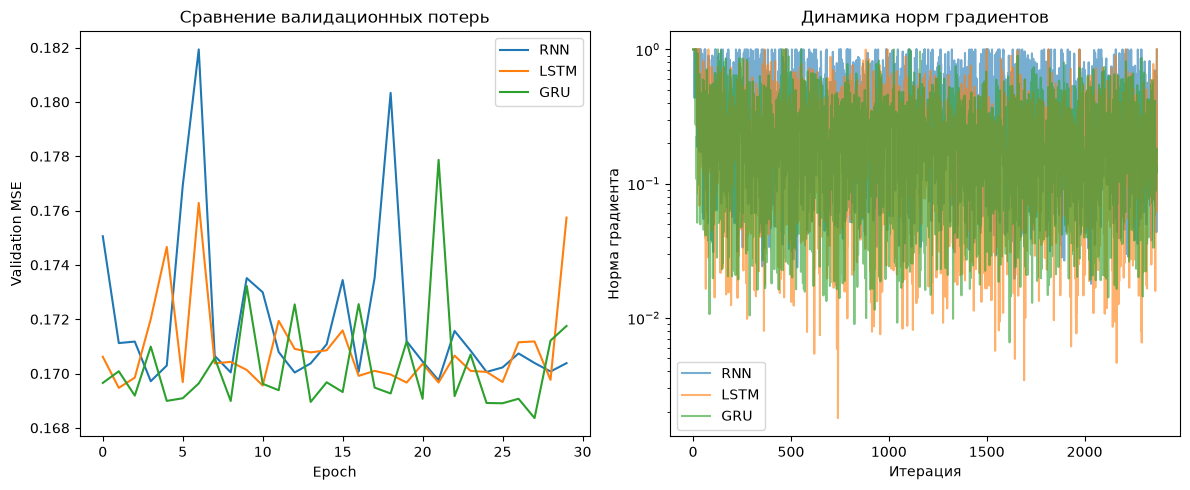

In [11]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(rnn_val_loss, label='RNN')
plt.plot(lstm_val_loss, label='LSTM')
plt.plot(gru_val_loss, label='GRU')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.legend()
plt.title('Сравнение валидационных потерь')

plt.subplot(1,2,2)
plt.plot(rnn_grads[:len(rnn_grads)], label='RNN', alpha=0.6)
plt.plot(lstm_grads[:len(lstm_grads)], label='LSTM', alpha=0.6)
plt.plot(gru_grads[:len(gru_grads)], label='GRU', alpha=0.6)
plt.xlabel('Итерация')
plt.ylabel('Норма градиента')
plt.yscale('log')
plt.legend()
plt.title('Динамика норм градиентов')
plt.tight_layout()
plt.show()

Теоретически надо было бы построить график такого плана:

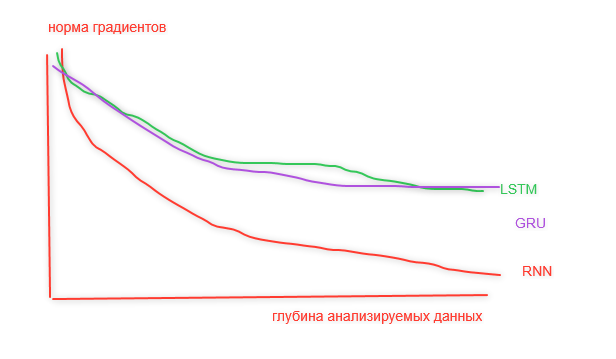

**Тот же график по данным.** Норма градиента функции потерь по скрытому состоянию $\lVert \partial L/\partial h_t \rVert$ для каждого шага $t$ — насколько сильно ошибка на выходе «дотягивается» до шага, отстоящего от конца на $T - t$ позиций. Для этого слой разворачивается вручную через ячейку `RNNCell`/`LSTMCell`/`GRUCell` с теми же весами (расчёт — на CPU, на копии модели).

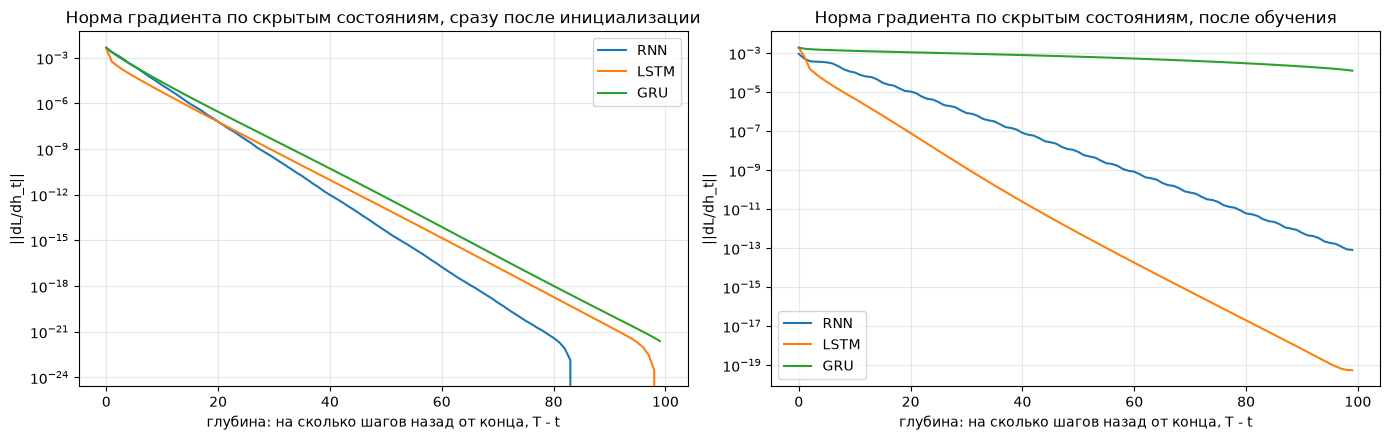

RNN: ||dL/dh|| на последнем шаге 9.04e-04, за 50 шагов до конца 8.49e-09, на первом шаге 8.05e-14 (отношение первый/последний = 8.9e-11)
LSTM: ||dL/dh|| на последнем шаге 1.83e-03, за 50 шагов до конца 5.98e-13, на первом шаге 5.48e-20 (отношение первый/последний = 3.0e-17)
GRU: ||dL/dh|| на последнем шаге 1.89e-03, за 50 шагов до конца 6.48e-04, на первом шаге 1.24e-04 (отношение первый/последний = 6.6e-02)


In [12]:
def hidden_grad_norms(model, X, y):
    """||dL/dh_t|| (среднее по батчу) для всех шагов t: разворачиваем слой ячейкой с теми же весами (на CPU)."""
    model = copy.deepcopy(model).cpu()
    rnn = getattr(model, 'rnn', None) or getattr(model, 'lstm', None) or getattr(model, 'gru', None)
    H = rnn.hidden_size
    if isinstance(rnn, nn.LSTM):
        cell = nn.LSTMCell(rnn.input_size, H)
    elif isinstance(rnn, nn.GRU):
        cell = nn.GRUCell(rnn.input_size, H)
    else:
        cell = nn.RNNCell(rnn.input_size, H, nonlinearity='tanh')
    with torch.no_grad():
        for a in ['weight_ih', 'weight_hh', 'bias_ih', 'bias_hh']:
            getattr(cell, a).copy_(getattr(rnn, f'{a}_l0'))
    h = torch.zeros(X.size(0), H); c = torch.zeros_like(h)
    hs = []
    for t in range(X.size(1)):
        if isinstance(cell, nn.LSTMCell):
            h, c = cell(X[:, t], (h, c))
        else:
            h = cell(X[:, t], h)
        h.retain_grad(); hs.append(h)
    loss = F.mse_loss(model.fc(h), y)
    loss.backward()
    return np.array([hh.grad.norm(dim=1).mean().item() for hh in hs])

Xg, yg = torch.tensor(val_X[:256]), torch.tensor(val_y[:256]).unsqueeze(1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, title, fresh in [(axes[0], 'сразу после инициализации', True), (axes[1], 'после обучения', False)]:
    for name, cls, trained in [('RNN', VanillaRNN, rnn_model), ('LSTM', LSTMModel, lstm_model), ('GRU', GRUModel, gru_model)]:
        torch.manual_seed(0)
        m = cls(input_size, hidden_size, output_size) if fresh else trained
        g = hidden_grad_norms(m, Xg, yg)
        ax.plot(np.arange(seq_len)[::-1], g, label=name)    # по оси x — расстояние от конца последовательности
    ax.set_yscale('log'); ax.set_xlabel('глубина: на сколько шагов назад от конца, T - t')
    ax.set_ylabel('||dL/dh_t||'); ax.set_title(f'Норма градиента по скрытым состояниям, {title}'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for name, m in [('RNN', rnn_model), ('LSTM', lstm_model), ('GRU', gru_model)]:
    g = hidden_grad_norms(m, Xg, yg)
    print(f'{name}: ||dL/dh|| на последнем шаге {g[-1]:.2e}, за 50 шагов до конца {g[-51]:.2e}, на первом шаге {g[0]:.2e} '
          f'(отношение первый/последний = {g[0] / g[-1]:.1e})')

**Задание для интерпретации:**
1. Какая модель показала наименьшую ошибку на валидации? Почему, на ваш взгляд?
2. Посмотрите на график норм градиентов. Для какой модели градиенты быстрее всего уменьшаются? Связано ли это с проблемой затухания?
3. Попробуйте увеличить длину последовательности до 200 (сгенерируйте новые данные) и повторите обучение (измените `seq_len=200` в ячейке генерации). Что изменилось?

#### Проверка: влияет ли на обучение шум в канале-индикаторе

В функции `generate_adding_problem_data` второй канал («индикатор позиции») сначала заполняется случайными числами из $U(0, 1)$, а затем в двух нужных позициях в него записываются единицы. Метка 1,0 плохо отличима от шума: значения больше 0,9 в среднем приходятся на 10 % позиций (их фактическое число посчитано ниже), и сети нужно выучить очень резкий порог, чтобы найти два нужных числа. В классической постановке adding problem индикатор — это нули и ровно две единицы.

Опыты с исправленным генератором (архитектуры и функция обучения — те же, по 30 эпох, как в опыте преподавателя):

1. **те же параметры, что в опыте преподавателя** — 5 000 последовательностей, `lr = 1e-3`: отличие только в данных;
2. **увеличенный бюджет обучения** — 20 000 последовательностей и `lr = 3e-3`: в adding problem сеть может долго находиться на «плато» с MSE ≈ 1/6 (ответ «всегда 1»), прежде чем найдёт решение, поэтому полезно дать ей больше шагов оптимизации;
3. **контроль** — тот же увеличенный бюджет, но исходный (шумный) генератор: чтобы отделить влияние исправления данных от влияния бюджета.

In [13]:
noise_close = (train_X[:, :, 1] > 0.9).sum(axis=1) - 2
print(f'в исходных данных: в среднем {noise_close.mean():.1f} «ложных» значений индикатора > 0.9 на последовательность')

def generate_adding_problem_data_fixed(num_samples, seq_len=100):
    """То же, но канал-индикатор содержит нули и ровно две единицы (классическая постановка)."""
    X, y = generate_adding_problem_data(num_samples, seq_len)
    X[:, :, 1] = (X[:, :, 1] == 1.0).astype(np.float32)   # оставляем только две метки
    return X, y

def run_adding(seq_len, epochs, gen, n_train=5000, lr=1e-3):
    """Обучает RNN, LSTM и GRU тем же train_model; по умолчанию — параметры опыта преподавателя."""
    np.random.seed(42); torch.manual_seed(42)
    trX, trY = gen(S(n_train, 256), seq_len)
    vX, vY = gen(S(1000, 128), seq_len)
    tl = DataLoader(AddingDataset(trX, trY), batch_size=64, shuffle=True)
    vl = DataLoader(AddingDataset(vX, vY), batch_size=64, shuffle=False)
    res = {}
    for name, cls in [('RNN', VanillaRNN), ('LSTM', LSTMModel), ('GRU', GRUModel)]:
        torch.manual_seed(0)
        m = cls(input_size, hidden_size, output_size)
        t0 = time.perf_counter()
        _, vloss, grads = train_model(m, tl, vl, epochs=epochs, lr=lr)
        res[name] = (vloss, grads, m, time.perf_counter() - t0)
        print(f'  {name}: val MSE по эпохам {np.round(vloss, 3).tolist()}  ({res[name][3]:.0f} с)')
    return res, (vX, vY)

E_ADD = S(30, 1)     # число эпох — как в опыте преподавателя
print(f'1) T = 100, исправленный индикатор, 5 000 последовательностей, lr = 1e-3, {E_ADD} эпох:')
fixed100, val100 = run_adding(100, E_ADD, generate_adding_problem_data_fixed)
print(f'\n2) T = 100, исправленный индикатор, 20 000 последовательностей, lr = 3e-3, {E_ADD} эпох:')
fixed100_big, val100_big = run_adding(100, E_ADD, generate_adding_problem_data_fixed, n_train=20000, lr=3e-3)
print(f'\n3) Контроль: T = 100, исходный (шумный) индикатор, 20 000 последовательностей, lr = 3e-3, {E_ADD} эпох:')
noisy100_big, _ = run_adding(100, E_ADD, generate_adding_problem_data, n_train=20000, lr=3e-3)

в исходных данных: в среднем 9.8 «ложных» значений индикатора > 0.9 на последовательность
1) T = 100, исправленный индикатор, 5 000 последовательностей, lr = 1e-3, 30 эпох:


Epoch 5: train_loss=0.1685, val_loss=0.1709


Epoch 10: train_loss=0.1669, val_loss=0.1720


Epoch 15: train_loss=0.1685, val_loss=0.1734


Epoch 20: train_loss=0.1667, val_loss=0.1709


...

Epoch 10: train_loss=0.1372, val_loss=0.1349


Epoch 15: train_loss=0.1214, val_loss=0.1249


Epoch 20: train_loss=0.1076, val_loss=0.1081


Epoch 25: train_loss=0.0895, val_loss=0.0816


Epoch 30: train_loss=0.0476, val_loss=0.0428
  GRU: val MSE по эпохам [0.16, 0.163, 0.169, 0.16, 0.158, 0.159, 0.148, 0.141, 0.133, 0.135, 0.14, 0.126, 0.123, 0.119, 0.125, 0.12, 0.114, 0.111, 0.109, 0.108, 0.102, 0.097, 0.103, 0.092, 0.082, 0.087, 0.065, 0.054, 0.056, 0.043]  (199 с)


**Задание 3.** Длина последовательности 200: как сказано в задании — исходный генератор (`seq_len=200` в ячейке генерации) с теми же параметрами, что в первом опыте (5 000 последовательностей, `lr = 1e-3`, 30 эпох), и для сравнения — исправленный генератор с теми же параметрами.

T = 200, исходный генератор, 5 000 последовательностей, lr = 1e-3, 30 эпох:


Epoch 5: train_loss=0.1700, val_loss=0.1712


Epoch 10: train_loss=0.1690, val_loss=0.1765


Epoch 15: train_loss=0.1683, val_loss=0.1734


Epoch 20: train_loss=0.1691, val_loss=0.1719


...

Epoch 10: train_loss=0.1669, val_loss=0.1733


Epoch 15: train_loss=0.1648, val_loss=0.1679


Epoch 20: train_loss=0.0596, val_loss=0.0543


Epoch 25: train_loss=0.0038, val_loss=0.0037


Epoch 30: train_loss=0.0016, val_loss=0.0017
  GRU: val MSE по эпохам [0.171, 0.179, 0.171, 0.178, 0.171, 0.171, 0.171, 0.171, 0.179, 0.173, 0.171, 0.173, 0.174, 0.17, 0.168, 0.166, 0.162, 0.102, 0.091, 0.054, 0.053, 0.041, 0.011, 0.005, 0.004, 0.003, 0.003, 0.003, 0.002, 0.002]  (99 с)


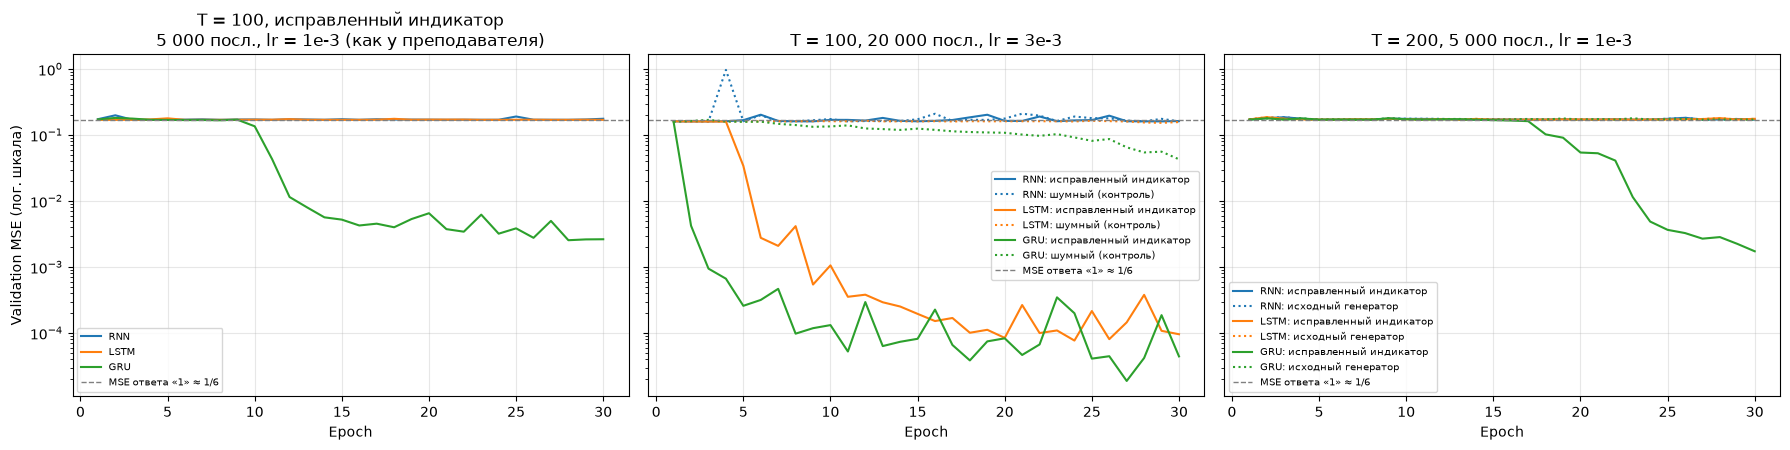

опыт                                                RNN     LSTM      GRU   (val MSE после последней эпохи)
T=100, исправл., 5 000, lr=1e-3                  0.1763   0.1697   0.0026
T=100, исправл., 20 000, lr=3e-3                 0.1627   0.0001   0.0000
T=100, шумный (контроль), 20 000, lr=3e-3        0.1609   0.1570   0.0428
T=200, исходный, 5 000, lr=1e-3                  0.1719   0.1760   0.1715
T=200, исправл., 5 000, lr=1e-3                  0.1715   0.1759   0.0017


In [14]:
print(f'T = 200, исходный генератор, 5 000 последовательностей, lr = 1e-3, {E_ADD} эпох:')
orig200, _ = run_adding(200, E_ADD, generate_adding_problem_data)
print(f'\nT = 200, исправленный индикатор, 5 000 последовательностей, lr = 1e-3, {E_ADD} эпох:')
fixed200, val200 = run_adding(200, E_ADD, generate_adding_problem_data_fixed)

ep = range(1, E_ADD + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for name, c in zip(['RNN', 'LSTM', 'GRU'], ['C0', 'C1', 'C2']):
    axes[0].plot(ep, fixed100[name][0], '-', color=c, label=f'{name}')
    axes[1].plot(ep, fixed100_big[name][0], '-', color=c, label=f'{name}: исправленный индикатор')
    axes[1].plot(ep, noisy100_big[name][0], ':', color=c, label=f'{name}: шумный (контроль)')
    axes[2].plot(ep, fixed200[name][0], '-', color=c, label=f'{name}: исправленный индикатор')
    axes[2].plot(ep, orig200[name][0], ':', color=c, label=f'{name}: исходный генератор')
for ax, t in zip(axes, ['T = 100, исправленный индикатор\n5 000 посл., lr = 1e-3 (как у преподавателя)',
                        'T = 100, 20 000 посл., lr = 3e-3', 'T = 200, 5 000 посл., lr = 1e-3']):
    ax.axhline(1 / 6, color='gray', ls='--', lw=1, label='MSE ответа «1» ≈ 1/6')
    ax.set_title(t); ax.set_xlabel('Epoch'); ax.set_yscale('log'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
axes[0].set_ylabel('Validation MSE (лог. шкала)')
plt.tight_layout(); plt.show()

print(f"{'опыт':<46}{'RNN':>9}{'LSTM':>9}{'GRU':>9}   (val MSE после последней эпохи)")
for title, res in [('T=100, исправл., 5 000, lr=1e-3', fixed100), ('T=100, исправл., 20 000, lr=3e-3', fixed100_big),
                   ('T=100, шумный (контроль), 20 000, lr=3e-3', noisy100_big), ('T=200, исходный, 5 000, lr=1e-3', orig200),
                   ('T=200, исправл., 5 000, lr=1e-3', fixed200)]:
    print(f"{title:<46}" + "".join(f"{res[n][0][-1]:>9.4f}" for n in ['RNN', 'LSTM', 'GRU']))

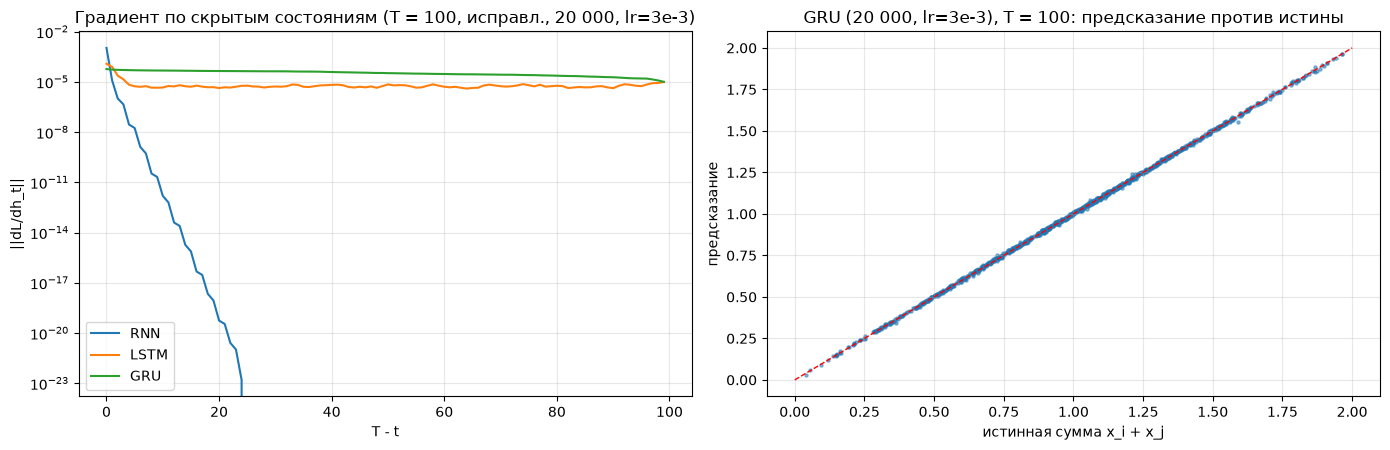

GRU (20 000, lr=3e-3): MSE = 0.0000, корреляция = 1.000


In [15]:
# Градиент по скрытым состояниям и предсказания лучшей модели на исправленных данных (T = 100)
runs100 = {'5 000, lr=1e-3': (fixed100, val100), '20 000, lr=3e-3': (fixed100_big, val100_big)}
best_run, best_name = min(((r, n) for r in runs100 for n in ['RNN', 'LSTM', 'GRU']), key=lambda rn: runs100[rn[0]][0][rn[1]][0][-1])
res_b, (vX_b, vY_b) = runs100[best_run]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
Xf, yf = torch.tensor(vX_b[:256]), torch.tensor(vY_b[:256]).unsqueeze(1)
for name in ['RNN', 'LSTM', 'GRU']:
    axes[0].plot(np.arange(100)[::-1], hidden_grad_norms(res_b[name][2], Xf, yf), label=name)
axes[0].set_yscale('log'); axes[0].set_xlabel('T - t'); axes[0].set_ylabel('||dL/dh_t||')
axes[0].set_title(f'Градиент по скрытым состояниям (T = 100, исправл., {best_run})'); axes[0].legend(); axes[0].grid(alpha=0.3)

m_best = res_b[best_name][2].eval()
with torch.no_grad():
    pred = m_best(torch.tensor(vX_b).to(device)).squeeze(1).cpu().numpy()
axes[1].scatter(vY_b, pred, s=5, alpha=0.5)
axes[1].plot([0, 2], [0, 2], 'r--', lw=1)
axes[1].set_xlabel('истинная сумма x_i + x_j'); axes[1].set_ylabel('предсказание')
axes[1].set_title(f'{best_name} ({best_run}), T = 100: предсказание против истины'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'{best_name} ({best_run}): MSE = {np.mean((pred - vY_b) ** 2):.4f}, корреляция = {np.corrcoef(pred, vY_b)[0, 1]:.3f}')

**1. Какая модель лучше на валидации.**

В опыте с параметрами заготовки (5 000 последовательностей, `lr = 1e-3`, 30 эпох) **не обучилась ни одна модель**. Итоговая val MSE — 0,170 у RNN, 0,176 у LSTM и 0,172 у GRU. Это уровень «ленивого» ответа «всегда 1» (MSE 0,1685): сети выучили только среднее значение суммы. Формально наименьшая ошибка у RNN, но разница — шум: кривые всех трёх моделей колеблются в одной полосе 0,168–0,182.

**Причина — в данных.** Канал-индикатор в генераторе заготовки — это шум $U(0, 1)$, в котором две нужные позиции помечены единицей. В среднем в каждой последовательности ещё 9,8 значений индикатора больше 0,9, и отличить настоящие метки от шума почти невозможно.

С исправленным генератором (в индикаторе нули и ровно две единицы) картина другая:

| опыт (val MSE после 30 эпох) | RNN | LSTM | GRU |
|---|---|---|---|
| T = 100, исправленный индикатор, 5 000, `lr = 1e-3` | 0,176 | 0,170 | **0,0026** |
| T = 100, исправленный индикатор, 20 000, `lr = 3e-3` | 0,163 | **0,0001** | **0,0000** |
| контроль: шумный индикатор, 20 000, `lr = 3e-3` | 0,161 | 0,157 | 0,043 |

- **Лучшая модель — GRU.** При тех же параметрах, что у преподавателя, она решает задачу: прорыв на 10–12-й эпохе, затем val MSE 0,003. При большем бюджете (в 4 раза больше данных и выше `lr`) решает уже на 2-й эпохе. Её предсказания почти точно совпадают с истинной суммой (корреляция 1,000).
- **LSTM** решает задачу только при большем бюджете (с 5–6-й эпохи), с параметрами заготовки остаётся на плато.
- **RNN** не решает ни в одном опыте.
- **Контроль** показывает, что главная помеха — шум в индикаторе: с тем же большим бюджетом на шумных данных LSTM не обучилась, а GRU лишь медленно снизила ошибку до 0,043.

**Почему так.** У LSTM и GRU есть путь, по которому информация и градиент проходят через много шагов почти без изменений. У LSTM это ячейка памяти с забывающим вентилем, у GRU — вентиль обновления, который позволяет просто копировать состояние. У простой RNN на каждом шаге состояние умножается на одну и ту же матрицу и проходит через tanh, поэтому сигнал о числе из первой половины последовательности (за 50–100 шагов до конца) не доживает до выхода.

**2. Нормы градиентов.**
- График из заготовки показывает норму градиента по всем параметрам на каждой итерации. Она ограничена обрезкой (`clip = 1.0`) и у всех моделей одинаково шумит между 0,01 и 1. О затухании по времени он ничего не говорит.
- Поэтому дополнительно построена норма $\lVert\partial L/\partial h_t\rVert$ в зависимости от того, сколько шагов от шага $t$ до конца. **Сразу после инициализации** у всех трёх моделей она падает экспоненциально, примерно до 10⁻²¹–10⁻²⁴ за 100 шагов: затухание градиента — общее свойство необученных рекуррентных сетей.
- **После обучения на данных заготовки:**
  - у GRU градиент почти не затухает: отношение первого шага к последнему 6,6·10⁻²;
  - у RNN — 8,9·10⁻¹¹;
  - у LSTM — 3,0·10⁻¹⁷, быстрее всех.

  LSTM здесь не обучилась и осталась в режиме «ленивого» ответа, её вентили, по-видимому, закрыты, и сигнал издалека не проходит. Затухание зависит не только от архитектуры, но и от того, чему сеть научилась.
- **После обучения на исправленных данных** (20 000 последовательностей) разница видна полностью. У RNN градиент становится меньше 10⁻²³ уже через ~25 шагов. У LSTM и GRU он почти постоянен на всех 100 шагах (порядка 10⁻⁵).

Да, это напрямую связано с затуханием: RNN не может выучить зависимость от числа из первой половины, потому что до неё не доходит градиент. У обученных LSTM и GRU он доходит.

**3. Длина 200.**
- **С генератором заготовки** ничего не изменилось: все три модели остаются на уровне ответа «1» (0,172, 0,176, 0,1715). При T = 100 они тоже не обучались.
- **С исправленным индикатором** при T = 200 обучается только GRU (0,0017 после 30 эпох), но прорыв наступает позже — на 17–23-й эпохе вместо 10–12-й при T = 100. RNN и LSTM на плато.

Чем длиннее последовательность, тем дальше первое число от выхода и тем дольше сеть ищет решение. Растёт и время: обучение RNN за 30 эпох — 72 с вместо 41 с при T = 100.

## **3. Эксперимент 2: Классификация тональности  комментариев на русском языке (RuSentiment)**

Используем датасет RuSentiment (отзывы о фильмах, размеченные по тональности: положительные, отрицательные, нейтральные).

**Задача:** обучить BiLSTM для классификации текста. Сравним однонаправленную LSTM и двунаправленную (BiLSTM), визуализируем скрытые состояния через t-SNE.

Labels meaning
0: NEUTRAL
1: POSITIVE
2: NEGATIVE

In [16]:
# Загружаем датасет с Hugging Face
dataset = load_dataset('Megnis/ru_sentiment_dataset-50000')
print(dataset)

# Посмотрим на распределение классов
from collections import Counter
labels = [ex['sentiment'] for ex in dataset['train']]
print(Counter(labels))

# Разделим на train, val, test (80/10/10) с помощью sklearn
from sklearn.model_selection import train_test_split

# Преобразуем Dataset в список для индексации
train_data = list(dataset['train'])
train_labels = [ex['sentiment'] for ex in train_data]

# Разделение: сначала 80% train, 20% temp
train_data_split, temp_data = train_test_split(
    train_data, test_size=0.2, random_state=42, stratify=train_labels
)

# Из temp делаем val и test (50/50 от 20% = 10% + 10%)
temp_labels = [ex['sentiment'] for ex in temp_data]
val_data, test_data = train_test_split(
    temp_data, test_size=0.5, random_state=42, stratify=temp_labels
)

print(f"Train size: {len(train_data_split)}, Val size: {len(val_data)}, Test size: {len(test_data)}")

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'text', 'sentiment'],
        num_rows: 48212
    })
})
Counter({2: 16158, 0: 16054, 1: 16000})


Train size: 38569, Val size: 4821, Test size: 4822


In [17]:
# Используем простой токенизатор на основе пробелов
def simple_tokenize(text, max_len=50):
    tokens = text.lower().split()[:max_len]
    return tokens

# Построим словарь только по обучающей части (в заготовке — по всему набору train_data, что даёт утечку из val/test)
vocab = {'<PAD>': 0, '<UNK>': 1}
for example in train_data_split:
    for token in simple_tokenize(example['text']):
        if token not in vocab:
            vocab[token] = len(vocab)

vocab_size = len(vocab)
print(f'Vocabulary size: {vocab_size}')
lens = [len(ex['text'].split()) for ex in train_data_split]
print(f'длина текста, слов: медиана {np.median(lens):.0f}, 95-й процентиль {np.percentile(lens, 95):.0f}; '
      f'длиннее 50 слов (обрезаются): {np.mean(np.array(lens) > 50):.1%}')
unk = np.mean([vocab.get(t, 1) == 1 for ex in val_data for t in simple_tokenize(ex['text'])])
print(f'доля неизвестных словарю токенов в валидации: {unk:.1%}')

Vocabulary size: 202739
длина текста, слов: медиана 76, 95-й процентиль 299; длиннее 50 слов (обрезаются): 66.4%


доля неизвестных словарю токенов в валидации: 7.9%


In [18]:
def text_to_ids(text, max_len=50):
    tokens = simple_tokenize(text, max_len)
    ids = [vocab.get(token, 1) for token in tokens]
    if len(ids) < max_len:
        ids += [0] * (max_len - len(ids))
    return ids[:max_len]

class RuSentimentDataset(Dataset):
    def __init__(self, data_list, max_len=50):
        self.texts = [ex['text'] for ex in data_list]
        self.labels = [ex['sentiment'] for ex in data_list]
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids = text_to_ids(self.texts[idx], self.max_len)
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long)

train_ds = RuSentimentDataset(train_data_split)   # в заготовке было train_data — весь набор, включая val и test
val_ds = RuSentimentDataset(val_data)
test_ds = RuSentimentDataset(test_data)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
test_loader = DataLoader(test_ds, batch_size=64)

In [19]:
class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim, n_layers=1, bidirectional=False, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, n_layers, batch_first=True,
                            bidirectional=bidirectional, dropout=dropout)
        self.fc = nn.Linear(hidden_dim * (2 if bidirectional else 1), output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        embedded = self.embedding(x)
        lstm_out, (hidden, _) = self.lstm(embedded)
        if self.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        hidden = self.dropout(hidden)
        out = self.fc(hidden)
        return out

# Параметры
embed_dim = 100
hidden_dim = 128
output_dim = 3  # три класса: neutral, positive, negative

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True).to(device)

In [20]:
def train_sentiment(model, train_loader, val_loader, epochs=10, lr=0.001):
    torch.manual_seed(0)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, val_accs = [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}')
        for X_batch, y_batch in pbar:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            pbar.set_postfix({'loss': loss.item()})
        train_losses.append(total_loss / len(train_loader))

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                pred = model(X_batch)
                _, predicted = torch.max(pred, 1)
                total += y_batch.size(0)
                correct += (predicted == y_batch).sum().item()
        val_acc = correct / total
        val_accs.append(val_acc)
        print(f'Epoch {epoch+1}: avg_train_loss={train_losses[-1]:.4f}, val_acc={val_acc:.4f}')

    return train_losses, val_accs

print("Training unidirectional LSTM...")
t0 = time.perf_counter()
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=S(10, 1))
t_uni = time.perf_counter() - t0

print("\nTraining bidirectional LSTM...")
t0 = time.perf_counter()
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=S(10, 1))
t_bi = time.perf_counter() - t0
print(f'время: Uni LSTM {t_uni:.0f} с, BiLSTM {t_bi:.0f} с')

Training unidirectional LSTM...


Epoch 1: avg_train_loss=1.0480, val_acc=0.5088


Epoch 2: avg_train_loss=0.9449, val_acc=0.5789


Epoch 3: avg_train_loss=0.8240, val_acc=0.6024


Epoch 4: avg_train_loss=0.6958, val_acc=0.6227


...

Epoch 6: avg_train_loss=0.1224, val_acc=0.6534


Epoch 7: avg_train_loss=0.0801, val_acc=0.6540


Epoch 8: avg_train_loss=0.0555, val_acc=0.6521


Epoch 9: avg_train_loss=0.0410, val_acc=0.6557


Epoch 10: avg_train_loss=0.0352, val_acc=0.6474
время: Uni LSTM 56 с, BiLSTM 73 с


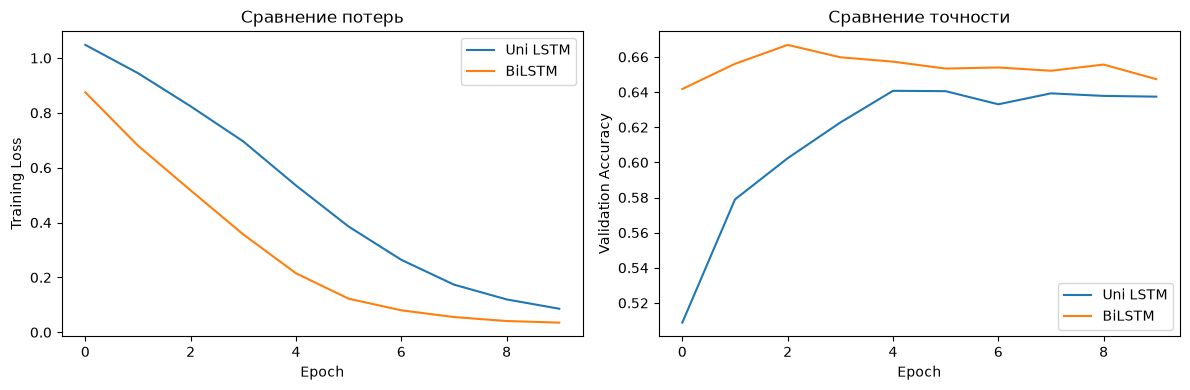

In [21]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

Uni LSTM: точность на тесте 0.6510


BiLSTM: точность на тесте 0.6667


              precision    recall  f1-score   support

     NEUTRAL      0.582     0.826     0.683      1606
    POSITIVE      0.729     0.472     0.573      1600
    NEGATIVE      0.752     0.702     0.726      1616

    accuracy                          0.667      4822
   macro avg      0.688     0.666     0.661      4822
weighted avg      0.688     0.667     0.661      4822



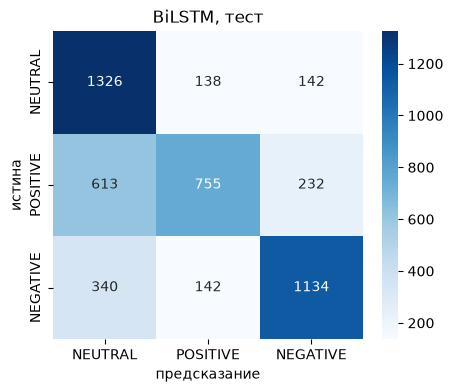

In [22]:
# Оценка на тестовой выборке (в заготовке модели сравниваются только по валидации)
def predict_all(model, loader):
    model.eval(); preds, ys = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            preds.append(model(X_batch.to(device)).argmax(1).cpu()); ys.append(y_batch)
    return torch.cat(preds).numpy(), torch.cat(ys).numpy()

names = ['NEUTRAL', 'POSITIVE', 'NEGATIVE']
for title, m in [('Uni LSTM', model_uni), ('BiLSTM', model_bi)]:
    p, yt = predict_all(m, test_loader)
    print(f'{title}: точность на тесте {accuracy_score(yt, p):.4f}')
p, yt = predict_all(model_bi, test_loader)
print(classification_report(yt, p, target_names=names, digits=3))
cm = confusion_matrix(yt, p)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)
plt.xlabel('предсказание'); plt.ylabel('истина'); plt.title('BiLSTM, тест'); plt.show()

### **3.1. Визуализация скрытых состояний с помощью t-SNE (3 класса)**

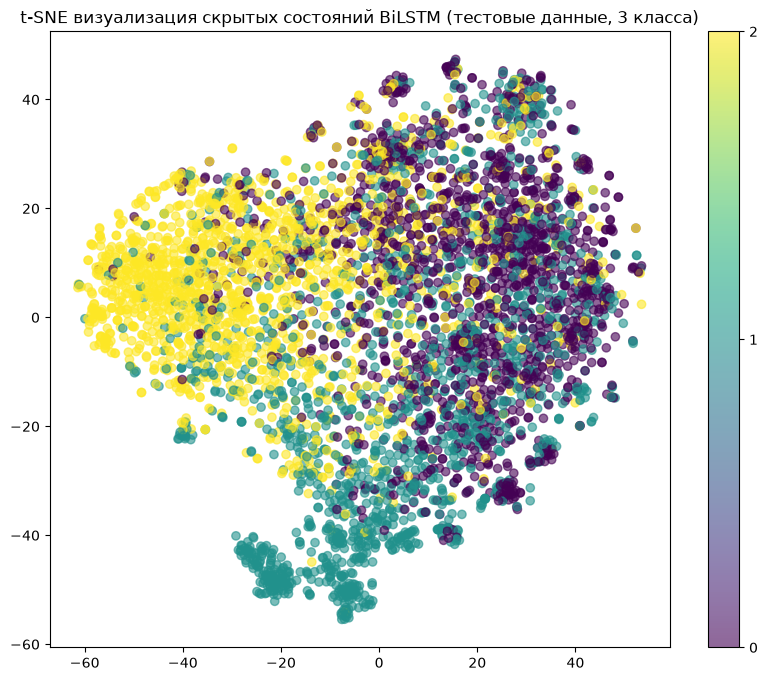

In [23]:
model_bi.eval()
hidden_states = []
labels = []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        embedded = model_bi.embedding(X_batch)
        lstm_out, (hidden, _) = model_bi.lstm(embedded)
        if model_bi.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        hidden_states.append(hidden.cpu().numpy())
        labels.append(y_batch.numpy())

hidden_states = np.vstack(hidden_states)
labels = np.hstack(labels)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
hidden_2d = tsne.fit_transform(hidden_states)

plt.figure(figsize=(10,8))
scatter = plt.scatter(hidden_2d[:,0], hidden_2d[:,1], c=labels, cmap='viridis', alpha=0.6)
plt.colorbar(scatter, ticks=[0,1,2])
plt.title('t-SNE визуализация скрытых состояний BiLSTM (тестовые данные, 3 класса)')
plt.show()

**Задание для интерпретации:**
1. Сравните точность однонаправленной и двунаправленной LSTM. Какая модель оказалась лучше и почему?
2. Посмотрите на t-SNE проекцию. Видны ли кластеры, соответствующие разным классам? Если нет, то что это может означать? Можно ли как-то эту информацию использовать?
3. (Дополнительно) Попробуйте изменить размер скрытого состояния (`hidden_dim`) и количество слоёв LSTM (`n_layers`). Как это влияет на точность и время обучения?

In [24]:
# К вопросу 1: в заготовке короткие тексты дополняются нулями (<PAD>) в КОНЦЕ, а однонаправленная LSTM берёт состояние
# после последнего шага — т. е. после чтения паддинга. Вариант однонаправленной LSTM, которая берёт состояние после
# последнего НАСТОЯЩЕГО токена (для однонаправленной сети это то же, что упаковка pack_padded_sequence); размеры и
# число эпох — те же.
class LastTokenLSTMSentiment(LSTMSentiment):
    def forward(self, x):
        assert not self.lstm.bidirectional
        lengths = (x != 0).sum(1).clamp(min=1)                       # число настоящих токенов в каждом тексте
        lstm_out, _ = self.lstm(self.embedding(x))
        last = lstm_out[torch.arange(x.size(0), device=x.device), lengths - 1]
        return self.fc(self.dropout(last))

extra = {}
torch.manual_seed(0)
m = LastTokenLSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False).to(device)
t0 = time.perf_counter(); _, acc = train_sentiment(m, train_loader, val_loader, epochs=S(10, 1))
extra['Uni LSTM: состояние после последнего токена, h=128'] = (acc, time.perf_counter() - t0, m)

# Дополнительно (вопрос 3): размер скрытого состояния и число слоёв для BiLSTM (столько же эпох, сколько у основной модели)
for hd, nl in [(64, 1), (256, 1), (128, 2)]:
    torch.manual_seed(0)
    m = LSTMSentiment(vocab_size, embed_dim, hd, output_dim, n_layers=nl, bidirectional=True).to(device)
    t0 = time.perf_counter(); _, acc = train_sentiment(m, train_loader, val_loader, epochs=S(10, 1))
    extra[f'BiLSTM h={hd}, слоёв {nl}'] = (acc, time.perf_counter() - t0, m)

print(f"\n{'модель':<52}{'лучшая val acc':>15}{'эпоха':>7}{'время, с':>10}{'параметров LSTM':>17}{'тест':>8}")
rows = [('Uni LSTM h=128 (заготовка)', uni_acc, t_uni, model_uni), ('BiLSTM h=128 (заготовка)', bi_acc, t_bi, model_bi)]
rows += [(k, v[0], v[1], v[2]) for k, v in extra.items()]
for name, acc, t, m in rows:
    p, yt = predict_all(m, test_loader)
    print(f"{name:<52}{max(acc):>15.4f}{int(np.argmax(acc)) + 1:>7}{t:>10.0f}{sum(p_.numel() for p_ in m.lstm.parameters()):>17,}"
          f"{accuracy_score(yt, p):>8.4f}")

Epoch 1: avg_train_loss=0.9848, val_acc=0.5787


Epoch 2: avg_train_loss=0.7764, val_acc=0.6345


Epoch 3: avg_train_loss=0.6273, val_acc=0.6474


Epoch 4: avg_train_loss=0.4823, val_acc=0.6530


Epoch 5: avg_train_loss=0.3488, val_acc=0.6519


...

Epoch 10: avg_train_loss=0.0349, val_acc=0.6343

модель                                               лучшая val acc  эпоха  время, с  параметров LSTM    тест
Uni LSTM h=128 (заготовка)                                   0.6407      5        56          117,760  0.6510


BiLSTM h=128 (заготовка)                                     0.6669      3        73          235,520  0.6667
Uni LSTM: состояние после последнего токена, h=128           0.6530      4        56          117,760  0.6551


BiLSTM h=64, слоёв 1                                         0.6517      2        67           84,992  0.6649


BiLSTM h=256, слоёв 1                                        0.6644      2        85          733,184  0.6584


BiLSTM h=128, слоёв 2                                        0.6625      2        99          630,784  0.6560


**Данные.** 48 212 текстов (по ~16 000 в каждом классе), разбиение 80/10/10: 38 569 / 4 821 / 4 822. Словарь построен только по обучающей части (202 739 слов; в заготовке он строился по всему набору, включая тест). Тексты длинные (медиана 76 слов), и при `max_len = 50` у 66 % текстов конец обрезается. Доля неизвестных словарю слов в валидации — 7,9 %.

**1. Однонаправленная или двунаправленная LSTM.**

| модель | лучшая val acc (эпоха) | точность на тесте после 10 эпох | время |
|---|---|---|---|
| Uni LSTM (заготовка) | 0,641 (5) | 0,651 | 56 с |
| **BiLSTM (заготовка)** | **0,667 (3)** | **0,667** | 73 с |
| Uni LSTM, состояние после последнего настоящего токена | 0,653 (4) | 0,655 | 56 с |

- **BiLSTM лучше** на 2,6 п. п. на валидации и на 1,6 п. п. на тесте, и учится быстрее: после первой эпохи 0,642 против 0,509. Классификатор получает два итоговых состояния. Прямой проход прочитал текст до конца, обратный — от конца к началу. Начало и конец текста представлены одинаково хорошо, а у однонаправленной сети начало длинного текста успевает «забыться».
- **Часть отставания однонаправленной LSTM — из-за дополнения нулями в конце.** В заготовке берётся состояние после последнего шага, то есть у коротких текстов — после чтения `<PAD>`. Если брать состояние после последнего настоящего токена (для однонаправленной сети это то же, что `pack_padded_sequence`), val acc растёт с 0,641 до 0,653, тест — с 0,651 до 0,655. Это меньше половины разрыва с BiLSTM: нулями дополнена только треть текстов (около 34 %), остальные обрезаны.
- **Обе модели быстро переобучаются.** Train loss падает до 0,09 и 0,035, а val acc достигает максимума на 3–5-й эпохе и дальше медленно снижается. 10 эпох для этой задачи много, ранняя остановка выбрала бы 3–5-ю эпоху.
- **Ошибки BiLSTM на тесте:**
  - нейтральный класс модель предсказывает слишком часто: recall 0,826 при precision 0,582;
  - 38 % положительных текстов (613 из 1 600) отнесены к нейтральным, recall положительного класса всего 0,472;
  - лучше всего распознаются отрицательные тексты (F1 0,726).

**2. t-SNE скрытых состояний BiLSTM.** Кластеры видны, но только частично.
- Отрицательные тексты образуют отдельную область слева.
- Положительные собраны внизу, в том числе в несколько маленьких плотных сгустков.
- Нейтральные занимают правую и центральную часть и сильно перемешаны с положительными, а на границе — и с отрицательными.

Это совпадает с матрицей ошибок: отрицательный класс модель отделяет хорошо, а граница «положительный — нейтральный» размыта. Значит, в представлении сети этих признаков недостаточно, чтобы их разделить.

Как это использовать:
- скрытые состояния можно брать как признаки текста для другого классификатора или для поиска похожих текстов;
- тексты из зоны перемешивания стоит просмотреть вручную: там могут быть неоднозначные тексты или ошибки разметки;
- маленькие плотные сгустки — по-видимому, группы очень похожих текстов, их стоит проверить на повторы.

**3. Размер скрытого состояния и число слоёв** (BiLSTM, по 10 эпох):

| вариант | параметров LSTM | лучшая val acc | тест | время |
|---|---|---|---|---|
| h = 64, 1 слой | 84 992 | 0,652 | 0,665 | 67 с |
| h = 128, 1 слой (заготовка) | 235 520 | **0,667** | **0,667** | 73 с |
| h = 256, 1 слой | 733 184 | 0,664 | 0,658 | 85 с |
| h = 128, 2 слоя | 630 784 | 0,663 | 0,656 | 99 с |

Увеличение скрытого состояния и второй слой качества не дают: все варианты на тесте в пределах 0,656–0,667, разница около 50 текстов из 4 822. Время растёт: с 67 до 85 с при росте h и до 99 с со вторым слоем. У всех вариантов лучшая эпоха — 2–3-я, дальше переобучение.

Узкое место не в размере LSTM. Больше всего параметров в слое эмбеддингов: 202 739 слов × 100 = 20,3 млн против 0,1–0,7 млн у LSTM. Его приходится учить с нуля на 38,6 тыс. текстов, и он быстро запоминает обучающую выборку. Помогли бы предобученные эмбеддинги, подслова вместо целых слов и ранняя остановка.

## **Заключение**

В этом практическом занятии мы:
- Убедились, что LSTM и GRU значительно лучше справляются с долгосрочными зависимостями, чем vanilla RNN.
- Визуализировали градиенты и увидели, что в RNN они быстро затухают.
- Применили BiLSTM для классификации русскоязычных текстов и сравнили с однонаправленной версией.
- Использовали t-SNE для визуализации скрытых представлений.

Попробуйте поэкспериментировать с гиперпараметрами и, возможно, применить предобученные эмбеддинги (FastText) для улучшения качества.

* Что нового узнали? Навыки/умения/знания.
* Обратная связь: что изменить по наполнению блокнотов материалам или способу подачи материала?

**Что нового.**
- Научился измерять затухание градиента по шагам времени, а не только смотреть на общую норму градиента. Для этого нужно развернуть слой ячейкой `RNNCell`/`LSTMCell`/`GRUCell` с теми же весами и взять градиенты по скрытым состояниям.
- Увидел на практике, что adding problem очень чувствительна к постановке: из-за шума в канале-индикаторе ни одна сеть не обучалась. После исправления данных GRU и LSTM решают задачу, а RNN — нет, как и предсказывает теория.
- Разобрался, как дополнение нулями влияет на однонаправленную LSTM и зачем нужна упаковка последовательностей (`pack_padded_sequence`).

**Что можно улучшить в материалах.**
- В генераторе adding problem канал-индикатор заполнен случайными числами, и метки 1,0 теряются среди значений, близких к 1. Из-за этого первое задание для интерпретации (какая модель лучше) не имеет содержательного ответа. В классической постановке индикатор — нули и две единицы.
- В заготовке классификации словарь и обучающий набор строились по всему датасету, включая валидацию и тест. Это утечка данных: точность на валидации завышена.
- График норм градиентов в заготовке — это общая норма по параметрам после обрезки, и затухания по времени он не показывает. Лучше сразу дать график $\lVert\partial L/\partial h_t\rVert$ по шагам.
- Описание датасета в тетрадке («отзывы о фильмах») стоит сверить с тем, что реально загружается: тексты в наборе длинные (медиана 76 слов), и при `max_len = 50` две трети из них обрезаются.